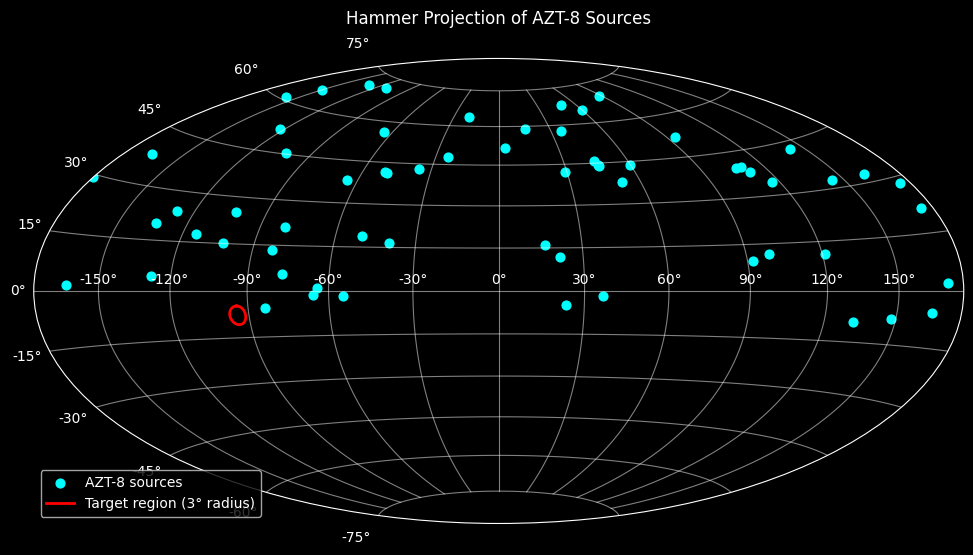

Sources inside target region:
[]


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u

# 1. Read the source catalogue
df = pd.read_csv("azt8.txt")

# 2. Convert coordinates
coords = SkyCoord(
    ra=df["Right_Ascension"].to_numpy(),
    dec=df["Declination"].to_numpy(),
    unit=(u.hourangle, u.deg),
    frame="icrs"
)

# 3. Wrap and reverse RA for astronomical sky map
ra_rad = -coords.ra.wrap_at(180 * u.deg).radian
dec_rad = coords.dec.radian

# 4. Create Hammer projection
fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(111, projection="hammer")

# 5. Plot sources
ax.scatter(
    ra_rad,
    dec_rad,
    s=40,
    color="cyan",
    label="AZT-8 sources"
)

# 6. Target region
center_ra = 94.3 * u.deg
center_dec = -7.8 * u.deg
radius = 3 * u.deg

center = SkyCoord(
    ra=center_ra,
    dec=center_dec,
    frame="icrs"
)

# 7. Generate an accurate spherical circle
angles = np.linspace(0, 360, 361) * u.deg

circle_coords = center.directional_offset_by(
    angles,
    radius
)

circle_ra_rad = -circle_coords.ra.wrap_at(
    180 * u.deg
).radian

circle_dec_rad = circle_coords.dec.radian


# Target region: RA = 94.3°, Dec = -7.8°
center = SkyCoord(ra=94.3*u.deg, dec=-7.8*u.deg)

radius = 3*u.deg
theta = np.linspace(0, 360, 361)*u.deg

# Calculate the circle boundary
circle = center.directional_offset_by(theta, radius)

# Convert to Hammer projection coordinates
circle_ra_rad = -circle.ra.wrap_at(180*u.deg).radian
circle_dec_rad = circle.dec.radian

# Draw hollow red circle
ax.plot(
    circle_ra_rad,
    circle_dec_rad,
    color="red",
    linewidth=2,
    label="Target region (3° radius)"
)

# 10. Formatting
ax.grid(True, alpha=0.5)
ax.set_title(
    "Hammer Projection of AZT-8 Sources",
    pad=25
)
ax.legend(loc="lower left")

plt.show()

# 11. Verify which sources fall inside the region
separations = coords.separation(center)
inside = separations <= radius

print("Sources inside target region:")
print(df.loc[inside, "Source_Name"].to_list())
